# Задача 2. Создание источника

Класс `Source` описывает излучение света в сцинтилляторе при взаимодействии частицы.

**Параметр:** $Y = 10\,000$ фотонов/МэВ.

* **Число фотонов.** Среднее число фотонов в событии $\langle n\rangle = Y\cdot E$. Реальное число фотонов в конкретном событии флуктуирует, поэтому по умолчанию оно разыгрывается по распределению Пуассона $n\sim\mathrm{Pois}(Y E)$; это не нарушает линейность выхода (линейно среднее). Параметром `fluctuate=False` можно получить детерминированное $n=\mathrm{round}(Y E)$.
* **Изотропное направление.** Равномерно по телесному углу $d\Omega=d\cos\theta\,d\varphi$, значит $\cos\theta\sim U(-1,1)$, $\varphi\sim U(0,2\pi)$.
* **Формат результата.** `numpy`-массив формы `(n, 3)` из единичных векторов — той же формы, что и массив координат ФЭУ в `Detector` (Задача 1), так что скалярные произведения считаются матричным умножением.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams['figure.figsize'] = (6, 3)
plt.rcParams['figure.autolayout'] = True

## Класс `Source`

In [2]:
class Source:
    """Изотропный точечный источник света в сцинтилляторе.

    Параметры
    ---------
    Y    : выход фотонов, фотонов/МэВ
    seed : начальное значение генератора случайных чисел (None — случайное)
    """

    def __init__(self, Y: float = 10_000, seed: int | None = None):
        if Y <= 0:
            raise ValueError("Выход фотонов Y должен быть положительным")
        self.Y = Y
        self.rng = np.random.default_rng(seed)

    def mean_photons(self, E: float) -> float:
        """Среднее число фотонов для энергии E (МэВ): линейно по E."""
        return self.Y * E

    def n_photons(self, E: float, fluctuate: bool = True) -> int:
        """Число фотонов в одном событии с энергией E (МэВ)."""
        if E < 0:
            raise ValueError("Энергия E не может быть отрицательной")
        mean = self.mean_photons(E)
        if fluctuate:
            return int(self.rng.poisson(mean))
        return int(round(mean))

    def random_directions(self, n: int) -> np.ndarray:
        """n изотропно распределённых единичных векторов, форма (n, 3)."""
        phi = self.rng.uniform(0.0, 2.0 * np.pi, n)
        cos_theta = self.rng.uniform(-1.0, 1.0, n)
        sin_theta = np.sqrt(1.0 - cos_theta**2)
        return np.stack([sin_theta * np.cos(phi),
                         sin_theta * np.sin(phi),
                         cos_theta], axis=1)

    def generate(self, E: float, fluctuate: bool = True) -> np.ndarray:
        """Начальные направления фотонов для события с энергией E (МэВ).

        Возвращает массив формы (n, 3), n = число фотонов в событии.
        """
        return self.random_directions(self.n_photons(E, fluctuate))

    def __repr__(self):
        return f"Source(Y={self.Y:_} фотонов/МэВ)"

In [3]:
src = Source(Y=10_000, seed=42)
print(src)

dirs = src.generate(E=1.0)
print("Событие E = 1 МэВ: число фотонов =", len(dirs), ", форма массива:", dirs.shape)
print(dirs[:3].round(3))

Source(Y=10_000 фотонов/МэВ)
Событие E = 1 МэВ: число фотонов = 10085 , форма массива: (10085, 3)
[[ 0.474 -0.584  0.659]
 [-0.24  -0.698 -0.675]
 [ 0.83   0.558 -0.006]]


## Тесты

Проверяем свойства, которые должны выполняться для любого набора входных данных.

In [4]:
def test_unit_vectors():
    d = Source(seed=1).random_directions(100_000)
    assert d.shape == (100_000, 3)
    assert np.allclose(np.linalg.norm(d, axis=1), 1.0, atol=1e-12)

def test_mean_direction_is_zero():
    n = 1_000_000
    d = Source(seed=2).random_directions(n)
    # каждая компонента: среднее 0, sigma = 1/sqrt(3 n)
    for k in range(3):
        assert abs(d[:, k].mean()) < 5 / np.sqrt(3 * n), d[:, k].mean()

def test_second_moments():
    # изотропия: <n_i n_j> = delta_ij / 3
    n = 1_000_000
    d = Source(seed=3).random_directions(n)
    M = d.T @ d / n
    assert np.allclose(M, np.eye(3) / 3, atol=5e-3), M

def test_cos_theta_uniform_chi2():
    n, bins = 1_000_000, 20
    d = Source(seed=4).random_directions(n)
    counts, _ = np.histogram(d[:, 2], bins=bins, range=(-1, 1))
    expected = n / bins
    chi2 = ((counts - expected) ** 2 / expected).sum()
    assert chi2 < 43.8, chi2          # квантиль 99.9 % для 19 степеней свободы

def test_phi_uniform_chi2():
    n, bins = 1_000_000, 20
    d = Source(seed=5).random_directions(n)
    phi = np.arctan2(d[:, 1], d[:, 0])
    counts, _ = np.histogram(phi, bins=bins, range=(-np.pi, np.pi))
    expected = n / bins
    chi2 = ((counts - expected) ** 2 / expected).sum()
    assert chi2 < 43.8, chi2

def test_octants_balanced():
    n = 800_000
    d = Source(seed=6).random_directions(n)
    code_ = (d > 0) @ np.array([1, 2, 4])
    counts = np.bincount(code_, minlength=8)
    assert np.all(np.abs(counts - n / 8) < 5 * np.sqrt(n / 8)), counts

def test_deterministic_count():
    s = Source(Y=10_000, seed=7)
    for E in (0.5, 1.0, 2.5, 7.3):
        assert len(s.generate(E, fluctuate=False)) == round(10_000 * E)

def test_poisson_count_mean_and_variance():
    s = Source(Y=10_000, seed=8)
    E, K = 1.0, 20_000
    n = np.array([s.n_photons(E) for _ in range(K)])
    mean = s.mean_photons(E)
    assert abs(n.mean() - mean) < 5 * np.sqrt(mean / K)
    assert abs(n.var() / mean - 1) < 0.05        # для Пуассона var = mean

def test_linearity_in_energy():
    s = Source(Y=10_000, seed=9)
    Es = np.array([0.1, 0.5, 1.0, 2.0, 5.0])
    means = np.array([np.mean([s.n_photons(E) for _ in range(300)]) for E in Es])
    slope = (means @ Es) / (Es @ Es)              # МНК через начало координат
    assert abs(slope / s.Y - 1) < 0.01, slope

def test_zero_energy_gives_no_photons():
    d = Source(seed=10).generate(0.0)
    assert d.shape == (0, 3)

def test_bad_input_raises():
    for bad in (lambda: Source(Y=0), lambda: Source().generate(-1.0)):
        try:
            bad()
        except ValueError:
            continue
        raise AssertionError("Ожидалось ValueError")

def test_reproducible():
    a = Source(seed=123).generate(1.0)
    b = Source(seed=123).generate(1.0)
    assert np.array_equal(a, b)

for name, f in list(globals().items()):
    if name.startswith("test_") and callable(f):
        f()
        print("OK ", name)

OK  test_unit_vectors
OK  test_mean_direction_is_zero
OK  test_second_moments
OK  test_cos_theta_uniform_chi2
OK  test_phi_uniform_chi2
OK  test_octants_balanced
OK  test_deterministic_count
OK  test_poisson_count_mean_and_variance
OK  test_linearity_in_energy
OK  test_zero_energy_gives_no_photons
OK  test_bad_input_raises
OK  test_reproducible


## Результаты

### Распределения направлений

E = 2 МэВ -> 20120 фотонов (ожидается в среднем 20000)


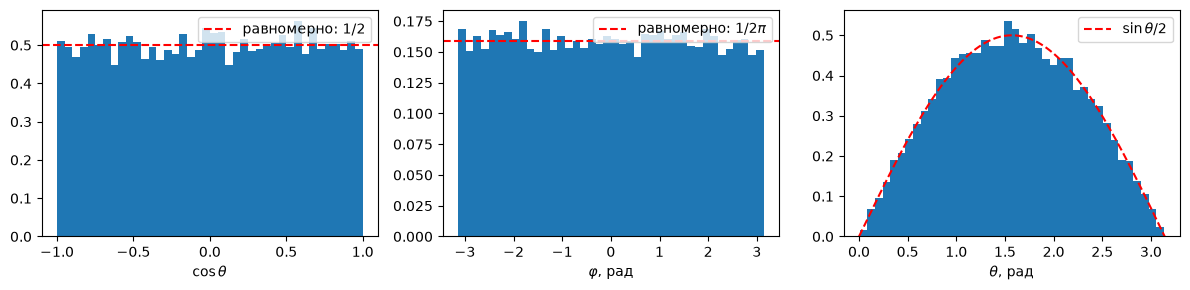

In [5]:
src = Source(Y=10_000, seed=42)
d = src.generate(E=2.0)
print(f"E = 2 МэВ -> {len(d)} фотонов (ожидается в среднем {src.mean_photons(2.0):.0f})")

theta = np.arccos(d[:, 2])
phi = np.arctan2(d[:, 1], d[:, 0])

fig, axs = plt.subplots(1, 3, figsize=(12, 3))
axs[0].hist(d[:, 2], bins=40, density=True)
axs[0].axhline(0.5, color='r', ls='--', label='равномерно: 1/2')
axs[0].set_xlabel(r'$\cos\theta$'); axs[0].legend()

axs[1].hist(phi, bins=40, density=True)
axs[1].axhline(1 / (2*np.pi), color='r', ls='--', label=r'равномерно: $1/2\pi$')
axs[1].set_xlabel(r'$\varphi$, рад'); axs[1].legend()

t = np.linspace(0, np.pi, 200)
axs[2].hist(theta, bins=40, density=True)
axs[2].plot(t, np.sin(t) / 2, 'r--', label=r'$\sin\theta/2$')
axs[2].set_xlabel(r'$\theta$, рад'); axs[2].legend()
plt.show()

Видно, что $\cos\theta$ и $\varphi$ распределены равномерно, а $\theta$ — по закону $\tfrac12\sin\theta$, как и должно быть для изотропного излучения (в $\theta$ равномерности нет: «кольцо» вокруг экватора больше, чем у полюса).

### Направления на единичной сфере

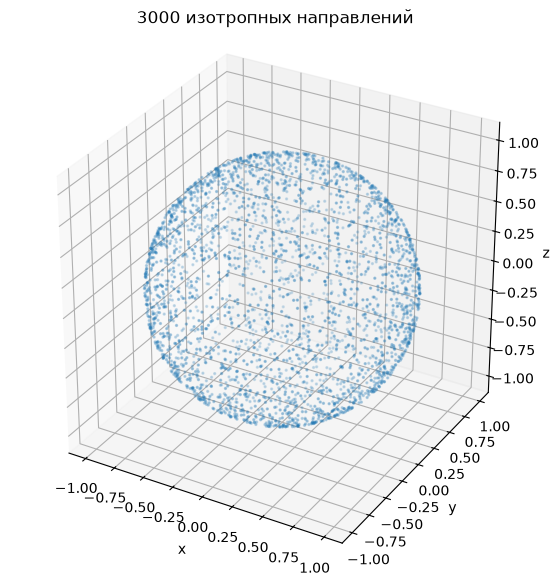

In [6]:
sub = Source(seed=0).random_directions(3000)

fig = plt.figure(figsize=(6, 6))
ax = fig.add_subplot(projection='3d')
ax.scatter(*sub.T, s=2, alpha=0.6)
ax.set_box_aspect((1, 1, 1))
ax.set_xlabel('x'); ax.set_ylabel('y'); ax.set_zlabel('z')
ax.set_title('3000 изотропных направлений')
plt.show()